In [1]:
import pandas as pd
import numpy as np

demo = pd.read_sas('../data/DEMO_L.xpt')
bmx = pd.read_sas('../data/BMX_L.xpt')
slq = pd.read_sas('../data/SLQ_L.xpt')
paq = pd.read_sas('../data/PAQ_L.xpt')

df = pd.merge(demo, bmx, on='SEQN', how='inner')
df = pd.merge(df, slq, on='SEQN', how='inner')
df = pd.merge(df, paq, on='SEQN', how='inner')

df = df[df['RIDAGEYR'] >= 20]

columns_to_keep = [
    'SEQN', 'RIDAGEYR', 'RIAGENDR', 'WTINT2YR', 'WTMEC2YR', 
    'BMXBMI', 'SLD013', 'PAD790Q', 'PAD790U', 'PAD810Q', 'PAD810U'
]
df = df[columns_to_keep]

df = df[~df['SLD013'].isin([77, 99])]
df = df[~df['PAD790Q'].isin([7777, 9999])]
df = df[~df['PAD810Q'].isin([7777, 9999])]
df = df.dropna()

df['PAD790Q'] = df['PAD790Q'].apply(lambda x: 0.0 if x < 1e-10 else x)
df['PAD810Q'] = df['PAD810Q'].apply(lambda x: 0.0 if x < 1e-10 else x)

def calc_weekly(row, q_col, u_col):
    val, unit = row[q_col], row[u_col]
    if val == 0:
        return 0
    
    u = str(unit).replace("b'", "").replace("'", "").upper()
    
    if u in ['1', '1.0', 'D']: return val * 7
    if u in ['2', '2.0', 'W']: return val
    if u in ['3', '3.0', 'M']: return val / 4.33
    if u in ['4', '4.0', 'Y']: return val / 52.0
    return 0

df['ModAct_PerWeek'] = df.apply(calc_weekly, args=('PAD790Q', 'PAD790U'), axis=1)

print(f"Final Analytical Population: {len(df)} people\n")

df['Gender'] = df['RIAGENDR'].replace({1.0: 'Male', 2.0: 'Female'})

print("Descriptive Statistics (BMI, Age, Sleep):")
print(df[['BMXBMI', 'RIDAGEYR', 'SLD013']].describe())

print("\nGender Frequency:")
gender_counts = df['Gender'].value_counts()
gender_pcts = df['Gender'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': gender_counts, 'Percentage (%)': gender_pcts}))
print("\n")

unweighted_bmi = df['BMXBMI'].mean()
weighted_bmi = np.average(df['BMXBMI'], weights=df['WTMEC2YR'])
print(f"Unweighted BMI Mean: {unweighted_bmi:.3f}")
print(f"Weighted BMI Mean: {weighted_bmi:.3f}")

q75_bmi, q25_bmi = np.percentile(df['BMXBMI'], [75 ,25])
q75_sleep, q25_sleep = np.percentile(df['SLD013'], [75 ,25])
print(f"BMI IQR: {q75_bmi - q25_bmi:.2f}")
print(f"Sleep IQR: {q75_sleep - q25_sleep:.2f}")

active_count = len(df[df['ModAct_PerWeek'] > 0])
print(f"Percentage reporting moderate activity: {(active_count/len(df))*100:.1f}%")

Final Analytical Population: 5865 people

Descriptive Statistics (BMI, Age, Sleep):
            BMXBMI     RIDAGEYR       SLD013
count  5865.000000  5865.000000  5865.000000
mean     29.830537    53.735209     8.254987
std       7.351145    17.137026     1.694295
min      14.100000    20.000000     2.000000
25%      24.700000    39.000000     7.500000
50%      28.500000    57.000000     8.000000
75%      33.600000    68.000000     9.000000
max      74.800000    80.000000    14.000000

Gender Frequency:
        Count  Percentage (%)
Gender                       
Female   3238       55.208866
Male     2627       44.791134


Unweighted BMI Mean: 29.831
Weighted BMI Mean: 29.683
BMI IQR: 8.90
Sleep IQR: 1.50
Percentage reporting moderate activity: 80.1%


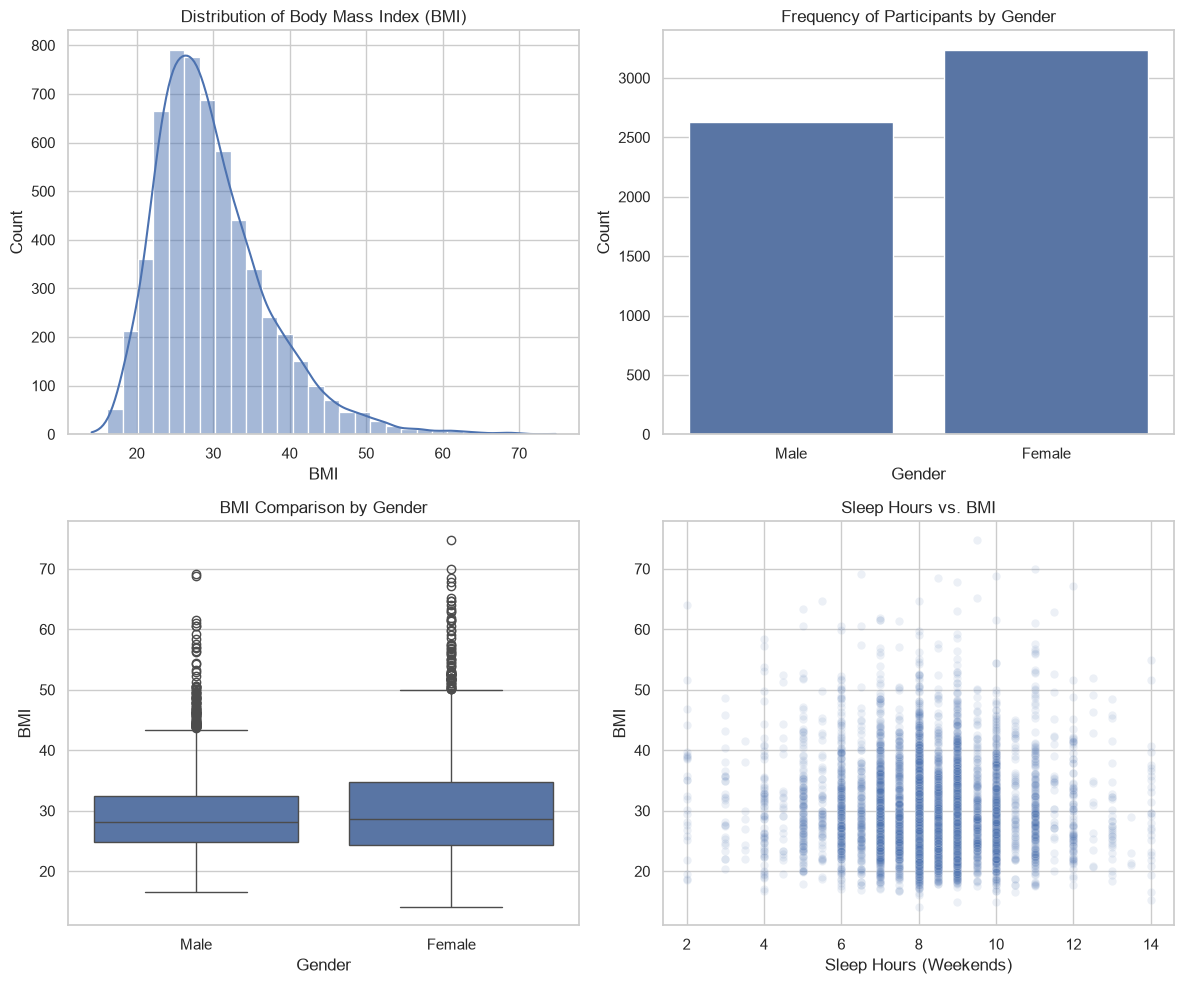

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

sns.histplot(df['BMXBMI'], kde=True, bins=30, ax=axes[0, 0])
axes[0, 0].set_title('Distribution of Body Mass Index (BMI)')
axes[0, 0].set_xlabel('BMI')
axes[0, 0].set_ylabel('Count')

sns.countplot(x='Gender', data=df, ax=axes[0, 1])
axes[0, 1].set_title('Frequency of Participants by Gender')
axes[0, 1].set_xlabel('Gender')
axes[0, 1].set_ylabel('Count')

sns.boxplot(x='Gender', y='BMXBMI', data=df, ax=axes[1, 0])
axes[1, 0].set_title('BMI Comparison by Gender')
axes[1, 0].set_xlabel('Gender')
axes[1, 0].set_ylabel('BMI')

sns.scatterplot(x='SLD013', y='BMXBMI', data=df, alpha=0.1, ax=axes[1, 1])
axes[1, 1].set_title('Sleep Hours vs. BMI')
axes[1, 1].set_xlabel('Sleep Hours (Weekends)')
axes[1, 1].set_ylabel('BMI')

plt.tight_layout()
plt.show()